# Seaborn Mini-Project: Penguin Species Analysis
Our goal is to understand how penguin species differ in body size, bill dimensions, and flipper length, then communicate those findings through visualizations and a final dashboard.

# 1. Project objectives
- Load and inspect a real-world dataset using Pandas.
- Identify and handle missing values appropriately.
- Compare penguin species using categorical plots.
- Explore relationships between numerical features using scatterplots and regression plots.
- Analyze correlations with a heatmap.
- Create a polished multi-plot dashboard.

# 2. Explanation
We'll use Seaborn's built-in `penguins` dataset, so you don't need to download a CSV manually.

It contains measurements from three penguin species: Adelie, Chinstrap, and Gentoo.

<table style="border-collapse: collapse; border: none; width: 100%; height: 350px;">
    <tr style="border: none; height: 100%;">
        <td style="width: 50%; padding: 2px; border: none; vertical-align: stretch; height: 100%;">
            <div style="width: 100%; height: 100%;">
                <img src="Images/Penguin_1.png" alt="Adelie Penguin" style="height: 100%; width: 100%; object-fit: cover; border-radius: 15px 0px 0px 15px; display: block;">
            </div>
        </td>
        <td style="padding: 2px; width: 50%; border: none; vertical-align: stretch; height: 100%;">
            <div style="display: flex; flex-direction: column; height: 100%; gap: 4px;">
                <div style="flex: 1; min-height: 0;">
                    <img src="Images/Penguin_2.png" alt="Chinstrap Penguin" style="width: 100%; height: 100%; object-fit: cover; border-radius: 0px 15px 0px 0px; display: block;">
                </div>
                <div style="flex: 1; min-height: 0;">
                    <img src="Images/Penguin_3.png" alt="Gentoo Penguin" style="width: 100%; height: 100%; object-fit: cover; border-radius: 0px 0px 15px 0px; display: block;">
                </div>
            </div>
        </td>
    </tr>
</table>

The main columns we'll work with are:
| Column | Meaning |
| :--- | :--- |
| `species` | Penguin species |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimeters |
| `bill_depth_mm` | Bill depth in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `sex` | Recorded sex of the penguin |

Some observations contain missing values, which we'll investigate in the next step rather than deleting rows automatically.

# 3. Steps
## Step 1:
### load the dataset and the libraries

In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visualization theme
sns.set_theme(style="whitegrid", context="talk")

# Load the dataset
df = sns.load_dataset("penguins")

### Inspect the dataset

In [4]:
# Display the first five rows
display(df.head())

# Dataset dimensions
print("\nDataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Missing values in each column
print("\nMissing values:")
display(df.isnull().sum())

# Number of duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



Dataset shape: (344, 7)

Columns:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Missing values:


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


Duplicate rows: 0


## Step 2:
### Data Cleaning and Missing-Value Analysis
In Step 1, we loaded the `penguins` dataset into `df`. Now we'll investigate its data quality, understand missing values, and decide how to prepare the data for analysis without accidentally losing useful information.

#### 1. Explanation — What are we checking?
We'll examine four things:
- Missing values: measurements or categories that were not recorded.
- Duplicate rows: repeated records that might or might not be errors.
- Data types: whether columns have appropriate numerical or categorical types.
- Cleaning decisions: which rows to retain, remove, or leave unchanged.

**Important:** missing values are not the same as zero. A missing body mass does not mean a penguin weighs zero grams!

#### 2. Code
**Count missing values:**

In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

display(missing_values)

# Calculate missing-value percentages
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

display(missing_percentage.rename("missing_percentage"))

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
Name: missing_percentage, dtype: float64

**Explanation:** `isnull()` identifies missing entries, `sum()` counts them, and `mean() * 100` calculates the percentage of missing values in each column.

**Visualize missing values:**

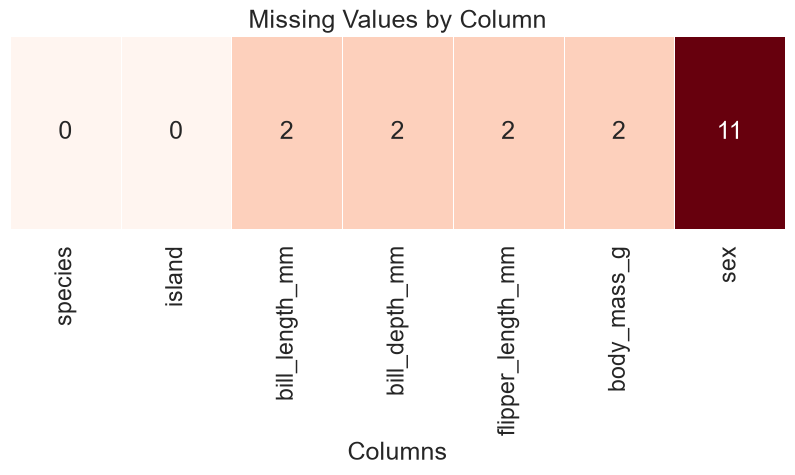

In [6]:
# Count missing values in each column
missing_values = df.isnull().sum().to_frame().T

plt.figure(figsize=(10, 2.5))

sns.heatmap(
    missing_values,
    annot=True,
    fmt="d",
    cmap="Reds",
    cbar=False,
    linewidths=0.5
)

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.yticks([])

plt.show()

**Inspect duplicates and data types:**

In [7]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Inspect column data types
print("\nData types:")
display(df.dtypes)

# View summary statistics
display(df.describe(include="all").T)

Duplicate rows: 0

Data types:


species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,Male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Don't delete duplicates automatically. Two penguins could legitimately have identical recorded measurements. We should investigate before removing any rows.

#### 3. Decide how to handle missing values
For the standard Seaborn penguins dataset, there are typically **344 rows and 7 columns**, with missing values in `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`, and `sex`.

A practical strategy for this project is:
- Keep the original `df` unchanged as our reference.
- Create a cleaned copy for the analyses that require complete measurements.
- Drop rows only when required columns are missing for a particular analysis.
- Avoid filling missing measurements with zero, because that would distort plots and summary statistics.

**Create a cleaned dataset**\
For our main physical-measurement analysis, we'll require species and all four measurement columns.

In [8]:
# Preserve the original dataset
df_original = df.copy()

# Select the columns required for measurement analysis
measurement_columns = [
    "species",
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Remove rows missing any required measurement
df_clean = df_original.dropna(
    subset=measurement_columns
).copy()

print("Original shape:", df_original.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", len(df_original) - len(df_clean))

# Verify required columns are complete
print("\nMissing values after cleaning:")
display(df_clean[measurement_columns].isnull().sum())

Original shape: (344, 7)
Cleaned shape: (342, 7)
Rows removed: 2

Missing values after cleaning:


species              0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

**Why not drop rows missing `sex`?**\
Because sex is not required for our initial species and body-measurement comparisons. Keeping those rows preserves useful observations.

We'll use `df_clean` for analyses that need complete measurements and retain `df_original` for other analyses.

## Step 3:
### Exploratory Data Analysis (EDA)
Now we'll explore the dataset before building our visualizations.\
Our first questions are:
- How many penguins belong to each species?
- Which islands are represented?
- What are the typical body mass and flipper length?
- How do the three species differ?

#### 1. Explanation
We'll use Pandas aggregation and summary statistics before plotting. This helps us understand what to look for in the charts.

#### 2. Code
**Species counts:**

In [9]:
# Count penguins in each species
species_counts = df_clean["species"].value_counts()

display(species_counts)

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

**Species and island summary:**

In [10]:
# Count observations for each species
print("Species counts:")
display(
    df_clean.groupby("species", observed=True)
        .size()
    .rename("count")
)

# Count observations for each island
print("\nIsland counts:")
display(
    df_clean["island"].value_counts()
)

Species counts:


species
Adelie       151
Chinstrap     68
Gentoo       123
Name: count, dtype: int64


Island counts:


island
Biscoe       167
Dream        124
Torgersen     51
Name: count, dtype: int64

**Numerical summary:**

In [11]:
# Summary statistics for physical measurements
measurement_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

display(
    df_clean.groupby("species", observed=True)[measurement_cols].mean().round(2)
)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.79,18.35,189.95,3700.66
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.50,14.98,217.19,5076.02


This table compares the average measurements of each species. Pay attention to `body_mass_g` and `flipper_length_mm` first, then compare bill length and bill depth.

#### 3. Interpret your results

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="Images/Penguin_4.png" alt="Adelie Penguin" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Adelie</h3>
			<ul>
				<li>Shortest average bill length: <b>38.79 mm</b></li>
				<li>Average bill depth: <b>18.35 mm</b></li>
				<li>Average flipper length: <b>189.95 mm</b></li>
				<li>Average body mass: <b>3,700.66 g</b></li>
			</ul>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="Images/Penguin_5.png" alt="Chinstrap Penguin" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Chinstrap</h3>
			<ul>
				<li>Longest average bill length: <b>48.83 mm </b></li>
				<li>Average bill depth: <b>18.42 mm</b></li>
				<li>Average flipper length: <b>195.82 mm</b></li>
				<li>Average body mass: <b>3,733.09 g</b></li>
			</ul>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="Images/Penguin_6.png" alt="Clustered heatmap" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Gentoo</h3>
			<ul>
				<li>Highest average body mass: <b>5,076.02 g</b></li>
				<li>Longest average flippers: <b>217.19 mm</b></li>
				<li>Smallest average bill depth: <b>14.98 mm</b></li>
				<li>Average bill length: <b>47.50 mm</b></li>
			</ul>
		</td>
	</tr>
</table>

The most noticeable difference is that **Gentoo penguins are substantially heavier and have longer flippers on average** than the other two species in this dataset.

**Chinstrap penguins have the longest average bill length**, while **Adelie penguins have the shortest**. These are group averages, so individual penguins can differ from their species' average.

#### 4. Visualize species differences
Let's create our first plot using `sns.barplot()`.

**Explanation**\
A barplot will compare the **average body mass** of each species. Seaborn calculates the mean by default, so we don't need to aggregate the data ourselves.

**Code**

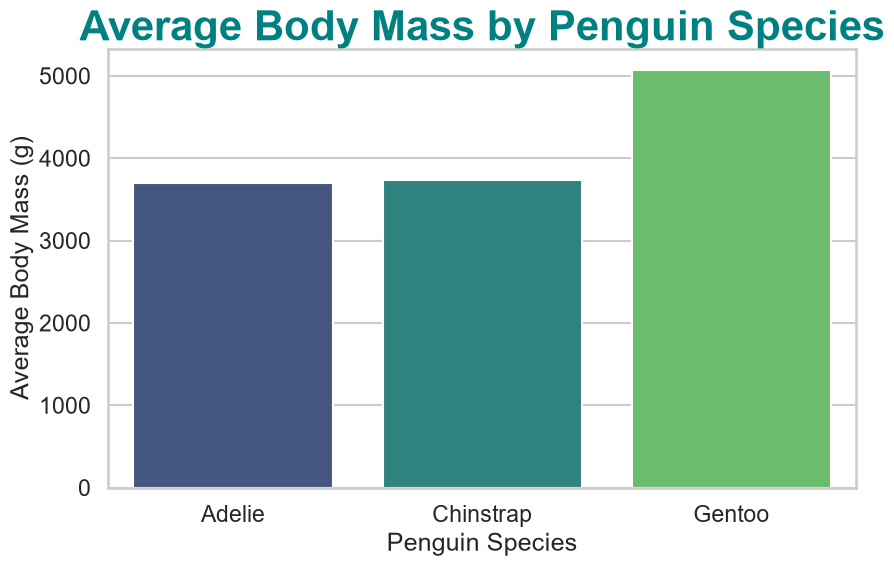

In [12]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette="viridis",
    errorbar=None,
    legend=False,
    dodge=False
)

plt.title(
    "Average Body Mass by Penguin Species",
    fontsize=30,
    fontweight="bold",
    color="teal"
)
plt.xlabel("Penguin Species")
plt.ylabel("Average Body Mass (g)")

plt.tight_layout()

plt.show()

**Output**
- Gentoo has the tallest bar: Highest Average Body Mass.
- Adelie has the shortest bar: Lowest Average Body Mass.
- Chinstrap and Adelie has relatively similar average body masses.

#### 5. Compare body mass distributions
**Explanation**\
Our earlier barplot compared average body mass. But averages don't tell us how much individual penguins vary.

A boxplot helps us see:
- **Middle line:** median body mass.
- **Box:** middle 50% of observations (interquartile range).
- **Whiskers and points:** spread and potential outliers.

**Code**

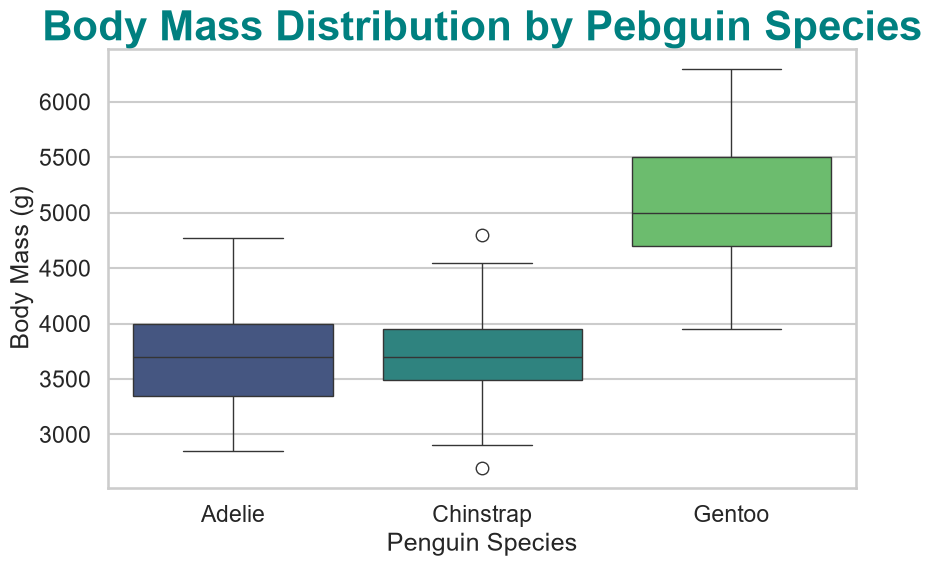

In [13]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette="viridis",
    legend=False,
    dodge=False
)

plt.title(
    "Body Mass Distribution by Pebguin Species",
    fontsize=30,
    fontweight="bold",
    color="teal"
)
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (g)")

plt.tight_layout()

plt.show()

**Output**
- Gentoo penguins generally has higher body masses.
- Adelie and Chinstrap distributions are much closer together.
- Look for points beyond the whiskers; these may be potential outliers, not necessarily errors.

#### 6. Flipper length vs body mass
**Explanation**\
Now we'll explore the relationship between two numerical variables:
- `flipper_length_mm` on the x-axis.
- `body_mass_g` on the y-axis.

We'll use `hue="species"` so each species has a different color. This can reveal whether the relationship differs between species.

**Code**

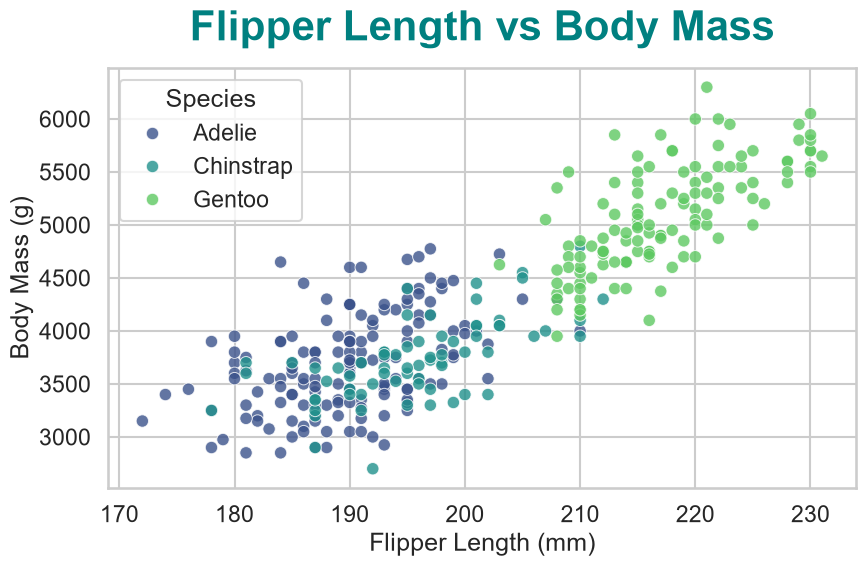

In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette="viridis",
    s=80,
    alpha=0.8
)

plt.title(
    "Flipper Length vs Body Mass",
    fontsize=30,
    fontweight="bold",
    color="teal",
    pad=20
)
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

plt.legend(title="Species")
plt.tight_layout()

plt.show()

**Output**\
You should generally see a positive relationship: penguins with longer flippers tend to have greater body mass. The species colors may form distinct clusters, especially for Gentoo penguins.

#### 7. Add a trend line
Let's use `sns.regplot()` to examine the overall linear trend.

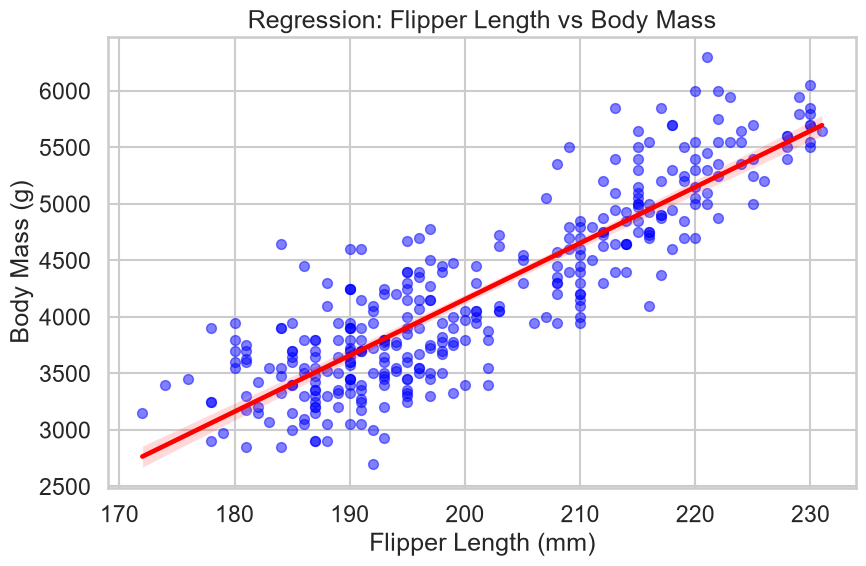

In [15]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    scatter_kws={"alpha": 0.5, "s": 50, "color": "blue"},
    line_kws={"color": "red"}
)

plt.title("Regression: Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

plt.tight_layout()

plt.show()

**Important:**\
This regression combines all three species.\
Differences between species may influence the overall trend, so we shouldn't interpret it as proof that longer flippers cause greater body mass.

### Review of the findings
- **Boxplot:** Gentoo penguins generally have a higher body mass than Adelie and Chinstrap penguins.
- **Scatterplot:** Flipper length and body mass show a positive relationship.
- **Species comparison:** Adelie and Chinstrap have similar average body masses, while Gentoo are substantially heavier on average.

**One useful nuance:**\
similar averages don't mean Adelie and Chinstrap have identical distributions. Their individual measurements can still vary considerably.

## Step 4:
### Correlation analysis
Now we'll quantify the relationships we observed in the scatterplot.
#### 1. Explanation
A correlation coefficient ranges from `-1` to `+1`:
- Near `+1`: strong positive linear relationship.
- Near `-1`: strong negative linear relationship.
- Near `0`: weak or no linear relationship.

Correlation describes association, not causation.

#### 2. Code
**Calculate the correlation matrix**

In [16]:
# Select numerical columns
numeric_df = df_clean.select_dtypes(include="number")

# Claculate correlation coefficients
correlation_matrix = numeric_df.corr()

# Display the correlation coefficients
display(correlation_matrix.round(3))

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


This calculates correlations between bill length, bill depth, flipper length, and body mass.

**Visualize the correlations**

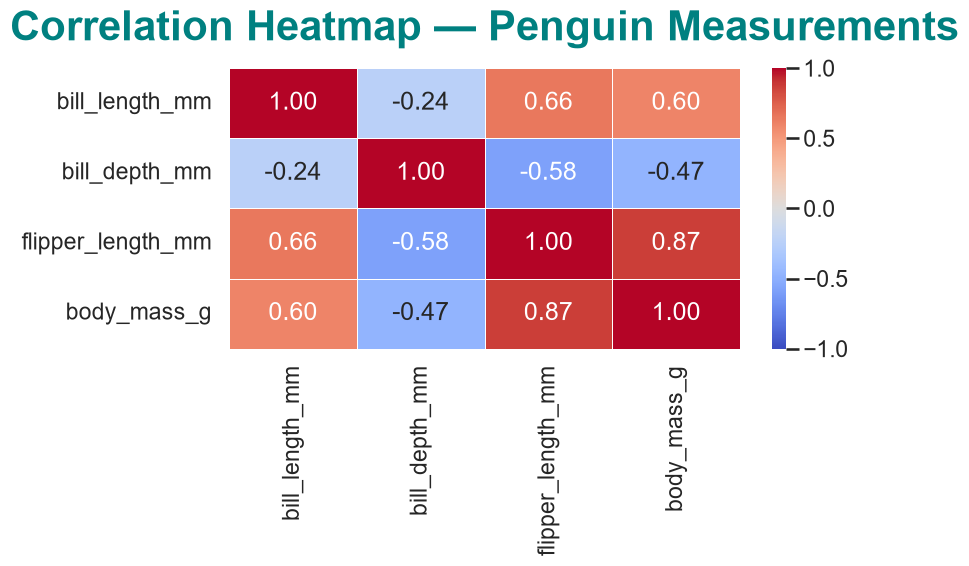

In [17]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    lw=0.5
)

plt.title(
    "Correlation Heatmap — Penguin Measurements",
    fontsize=30,
    fontweight="bold",
    color="teal",
    pad=20
)

plt.tight_layout()

plt.show()

The correlation matrix and heatmap gives us some useful findings. The strongest relationship is between flipper length and body mass, with a correlation of `+0.871`. That supports what you observed in the scatterplot.

#### 3. Interpret your correlation matrix

<table style="background-color: #000000; border-collapse: collapse; border: none; width: 100%; color: #FFFFFF; font-family: sans-serif; padding: 15px;">
    <tr style="border: none;">
        <!-- Left Column: Big Green Number -->
        <td style="width: 25%; text-align: center; vertical-align: middle; border: none; font-size: 28px; font-weight: bold; color: #00FF00; padding: 20px;">
            +0.871
        </td>
        <!-- Right Column: Text Information -->
        <td style="width: 75%; text-align: left; vertical-align: middle; border: none; padding: 20px 20px 20px 0px;">
            <!-- Title -->
            <div style="font-size: 18px; font-weight: bold; margin-bottom: 8px;">
                Flipper length &harr; Body mass
            </div>
            <!-- Badge / Pill -->
            <div style="display: inline-block; background-color: #032510; color: #00FF00; font-size: 12px; font-weight: bold; padding: 4px 10px; border-radius: 12px; margin-bottom: 12px;">
                Strong positive
            </div>
            <!-- Description -->
            <div style="font-size: 15px; color: #E0E0E0; line-height: 1.4;">
                Penguins with longer flippers tend to have greater body mass.
            </div>
        </td>
    </tr>
	<tr style="border: none;">
        <!-- Left Column: Big Green Number -->
        <td style="width: 25%; text-align: center; vertical-align: middle; border: none; font-size: 28px; font-weight: bold; padding: 20px;">
            +0.656
        </td>
        <!-- Right Column: Text Information -->
        <td style="width: 75%; text-align: left; vertical-align: middle; border: none; padding: 20px 20px 20px 0px;">
            <!-- Title -->
            <div style="font-size: 18px; font-weight: bold; margin-bottom: 8px;">
                Bill length &harr; Flipper Length
            </div>
            <!-- Badge / Pill -->
            <div style="display: inline-block; background-color: rgba(128, 128, 128, 0.5); font-size: 12px; font-weight: bold; padding: 4px 10px; border-radius: 12px; margin-bottom: 12px;">
                Moderately strong positive relationship
            </div>
            <!-- Description -->
            <div style="font-size: 15px; color: #E0E0E0; line-height: 1.4;">
                Longer bills tend to be associated with longer flippers.
            </div>
        </td>
    </tr>
	<tr style="border: none;">
        <!-- Left Column: Big Green Number -->
        <td style="width: 25%; text-align: center; vertical-align: middle; border: none; font-size: 28px; font-weight: bold; padding: 20px;">
            -0.584
        </td>
        <!-- Right Column: Text Information -->
        <td style="width: 75%; text-align: left; vertical-align: middle; border: none; padding: 20px 20px 20px 0px;">
            <!-- Title -->
            <div style="font-size: 18px; font-weight: bold; margin-bottom: 8px;">
                Bill depth &harr; Flipper Length
            </div>
            <!-- Badge / Pill -->
            <div style="display: inline-block; background-color: rgba(128, 128, 128, 0.5); font-size: 12px; font-weight: bold; padding: 4px 10px; border-radius: 12px; margin-bottom: 12px;">
                Moderately negative relationship
            </div>
            <!-- Description -->
            <div style="font-size: 15px; color: #E0E0E0; line-height: 1.4;">
                Penguins with greater bill depth tend to have shorter flippers in the combined dataset.
            </div>
        </td>
    </tr>
	<tr style="border: none;">
        <!-- Left Column: Big Green Number -->
        <td style="width: 25%; text-align: center; vertical-align: middle; border: none; font-size: 28px; font-weight: bold; color: #FF3333; padding: 20px;">
            -0.235
        </td>
        <!-- Right Column: Text Information -->
        <td style="width: 75%; text-align: left; vertical-align: middle; border: none; padding: 20px 20px 20px 0px;">
            <!-- Title -->
            <div style="font-size: 18px; font-weight: bold; margin-bottom: 8px;">
                Bill length &harr; Bill depth
            </div>
            <!-- Badge / Pill -->
            <div style="display: inline-block; background-color: #8B0000; color: #FF3333; font-size: 12px; font-weight: bold; padding: 4px 10px; border-radius: 12px; margin-bottom: 12px;">
                weak negative relationship
            </div>
            <!-- Description -->
            <div style="font-size: 15px; color: #E0E0E0; line-height: 1.4;">
                The linear association is relatively weak.
            </div>
        </td>
    </tr>
</table>

The remaining values are also informative:
- `bill_length_mm` and `body_mass_g`: **+0.595**, a positive relationship.
- `bill_depth_mm` and `body_mass_g`: **−0.472**, a moderate negative relationship.

**Important insight:**\
these correlations combine all three species. Species differences may contribute substantially to the relationships, so correlation doesn't establish causation or necessarily describe the relationship within each species.

## Step 5
### Build the final dashboard
Now let's combine the main findings into a single 2×2 dashboard.

We'll include:
1. Average body mass by species.
2. Body mass distributions by species.
3. Flipper length versus body mass.
4. Correlation heatmap.

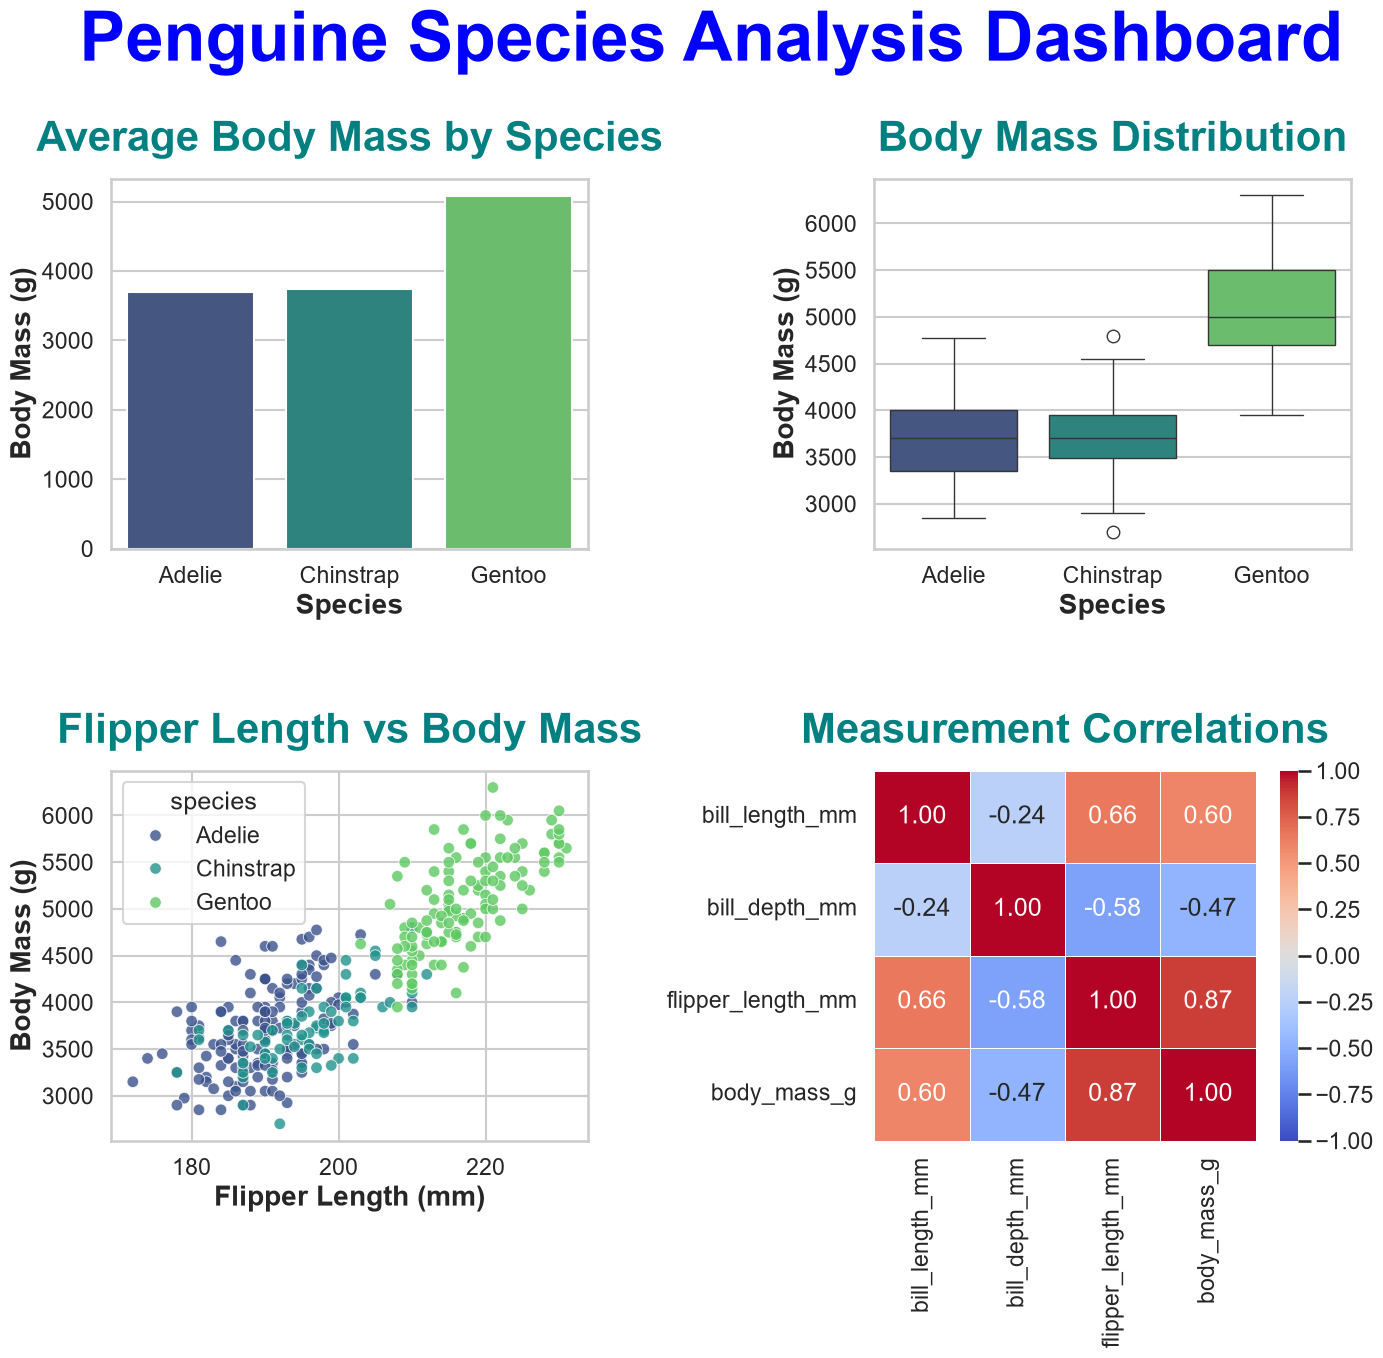

In [44]:
# Prepare the correlation matrix
numeric_df = df_clean.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

# Create the dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# 1. Average body mass by species
sns.barplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette="viridis",
    errorbar=None,
    legend=False,
    dodge=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "Average Body Mass by Species",
    fontsize=30,
    fontweight="bold",
    color="teal",
    pad=20.0
)
axes[0, 0].set_xlabel("Species", fontsize=20, fontweight="bold")
axes[0, 0].set_ylabel("Body Mass (g)", fontsize=20, fontweight="bold")

# 2. Body mass distribution
sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette="viridis",
    dodge=False,
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Body Mass Distribution",
    fontsize=30,
    fontweight="bold",
    color="teal",
    pad=20.0
)
axes[0, 1].set_xlabel("Species", fontsize=20, fontweight="bold")
axes[0, 1].set_ylabel("Body Mass (g)", fontsize=20, fontweight="bold")

# 3. Flipper length vs body mass
sns.scatterplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette="viridis",
    s=70,
    alpha=0.8,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Flipper Length vs Body Mass",
    fontsize=30,
    fontweight="bold",
    color="teal",
    pad=20.0
)
axes[1, 0].set_xlabel("Flipper Length (mm)", fontsize=20, fontweight="bold")
axes[1, 0].set_ylabel("Body Mass (g)", fontsize=20, fontweight="bold")

# 4. Correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    lw=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Measurement Correlations",
    fontsize=30,
    fontweight="bold",
    color="teal",
    pad=20.0
)

# Overall dashboard title
fig.suptitle(
    "Penguine Species Analysis Dashboard",
    fontsize=50,
    fontweight="bold",
    color="blue"
)

fig.subplots_adjust(
    hspace=0.60,
    wspace=0.60,
    top=0.85
)

# Save the dashboard
fig.savefig(
    "Images/Penguin_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**What do these parameters mean?**
- `"images/penguin_dashboard.png"` — the image path and filename.
- `dpi=300` — high resolution, suitable for GitHub documentation.
- `bbox_inches="tight"` — trims unnecessary whitespace around the dashboard.

We have already revealed some interesting findings:
- Gentoo penguins have the highest average body mass and longest average flippers.
- Adelie and Chinstrap penguins have similar average body masses.
- Flipper length and body mass have a strong positive correlation of approximately `+0.871` in your cleaned dataset.

## Step 6
### Findings and conclusion
#### 1. Explanation
The dashboard contains four plots. Now we'll turn those visualizations and the correlation matrix into clear, evidence-based findings.

We'll use the actual summary statistics you calculated, rather than making claims that the plots alone can't support.

#### 2. Code
**Generate a summary of `key findings`**

In [43]:
# Average body mass by species
body_mass_summary = (
    df_clean.groupby("species", observed=True)["body_mass_g"].mean().sort_values(ascending=False)
)

# Average flipper length by species
flipper_summary = (
    df_clean.groupby("species", observed=True)["flipper_length_mm"].mean().sort_values(ascending=False)
)

# Correlation between flipper length and body mass
flipper_body_mass_corr = (
    df_clean["flipper_length_mm"].corr(df_clean["body_mass_g"])
)

print("Average body mass by species (g):")
display(body_mass_summary.round(2))

print("\nAverage flipper length by species (mm):")
display(flipper_summary.round(2))

print("\nCorrelation between flipper length and body mass:", round(flipper_body_mass_corr, 3))

Average body mass by species (g):


species
Gentoo       5076.02
Chinstrap    3733.09
Adelie       3700.66
Name: body_mass_g, dtype: float64


Average flipper length by species (mm):


species
Gentoo       217.19
Chinstrap    195.82
Adelie       189.95
Name: flipper_length_mm, dtype: float64


Correlation between flipper length and body mass: 0.871


This makes your findings reproducible: if the dataset changes, the reported statistics update automatically.

#### 3. Key Findings

1. **Body mass differences:** Gentoo penguins have the highest average body mass, at approximately `5,076 g`. Adelie and Chinstrap penguins have much lower and relatively similar averages.

2. **Flipper length:** Gentoo penguins also have the longest average flippers, at approximately `217.19 mm`.

3. **Bill measurements:** Chinstrap penguins have the longest average bill length `48.83 mm`, while Gentoo penguins have the smallest average bill depth `14.98 mm`.

4. **Relationship between flipper length and body mass:** The correlation is approximately `+0.871`, indicating a strong positive linear association in the cleaned dataset.

5. **Species distributions:** The boxplot and scatterplot help reveal variation among individual penguins and differences between species that cannot be understood from averages alone.

#### 4. Conclusion

This exploratory data analysis shows clear differences in physical measurements among Adelie, Chinstrap, and Gentoo penguins. Gentoo penguins are heavier on average and have longer flippers, while Chinstrap penguins have the longest average bills.

Flipper length and body mass have a strong positive correlation across the cleaned dataset. However, correlation does not establish causation, and differences between species may contribute to the observed relationship.

The project demonstrates how Pandas and Seaborn can be used together to clean data, summarize measurements, explore relationships, and communicate findings through visualizations.

# Project Complete